# Part 1: Data pipeline
Downloads 24 months of NYC TLC yellow cab trips (Sep 2024 to Aug 2026), standardizes schema drift, removes bad rows by rule and adds time, holiday, airport and congestion-zone features. Output: `taxi.duckdb` with 85,286,518 clean trips, a zero-filled zone × hour demand table and a daily summary.

Part of [NYC Yellow Cab: demand, pricing and forecasting](../README.md). Next: [Part 2, EDA](P2_eda.ipynb).

In [1]:
# Part 1 data preparation
# 1.1 import libs, mount drives, set configs
import os, sys, time, urllib.request
from pathlib import Path
import duckdb, pandas as pd

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
  from google.colab import drive
  drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/nyc-yellow-cab")
RAW, CLEAN, AGG = BASE / 'raw', BASE / 'clean', BASE / 'agg'
for p in (RAW, CLEAN, AGG):
  p.mkdir(parents=True, exist_ok=True)

DEV_MODE = False                        # True = one month only; set False for the full 24 months
DEV_MONTHS = ['2025-10']
ALL_MONTHS = [str(m) for m in pd.period_range('2024-09', '2026-08', freq='M')]
MONTHS = DEV_MONTHS if DEV_MODE else ALL_MONTHS

URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{}.parquet"
ZONE_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

con = duckdb.connect()
con.execute("SET memory_limit='8GB'; SET temp_directory='/tmp/duckdb_spill'")
print(f"{len(MONTHS)} month(s) → {BASE}")

Mounted at /content/drive
24 month(s) → /content/drive/MyDrive/nyc-yellow-cab


In [2]:
# 1.2 fault-tolerant download
def download(url, dest, tries=3):
  if dest.exists() and dest.stat().st_size > 0:
    return "cached"
  for i in range(tries):
    try:
      tmp = dest.with_suffix(".part")
      urllib.request.urlretrieve(url, tmp)
      tmp.rename(dest)
      return "downloaded"
    except Exception as e:
      if i == tries - 1:
        raise RuntimeError(f"{url}: {e}")
      time.sleep(5 * (i + 1))

for m in MONTHS:
  f = RAW / f"yellow_tripdata_{m}.parquet"
  status = download(URL.format(m), f)
  n = con.sql(f"SELECT count(*) FROM '{f}'").fetchone()[0]
  print(f"{m}: {status}, {n:,} rows, {f.stat().st_size/1e6:.0f} MB")

download(ZONE_URL, RAW / "taxi_zone_lookup.csv")
zones = pd.read_csv(RAW / "taxi_zone_lookup.csv")
zones.head()

2024-09: downloaded, 3,633,030 rows, 61 MB
2024-10: downloaded, 3,833,771 rows, 64 MB
2024-11: downloaded, 3,646,369 rows, 61 MB
2024-12: downloaded, 3,668,371 rows, 62 MB
2025-01: downloaded, 3,475,226 rows, 59 MB
2025-02: downloaded, 3,577,543 rows, 60 MB
2025-03: downloaded, 4,145,257 rows, 70 MB
2025-04: downloaded, 3,970,553 rows, 67 MB
2025-05: downloaded, 4,591,845 rows, 78 MB
2025-06: downloaded, 4,322,960 rows, 74 MB
2025-07: downloaded, 3,898,963 rows, 67 MB
2025-08: downloaded, 3,574,091 rows, 62 MB
2025-09: downloaded, 4,251,015 rows, 72 MB
2025-10: cached, 4,428,699 rows, 75 MB
2025-11: downloaded, 4,181,444 rows, 71 MB
2025-12: downloaded, 4,305,006 rows, 74 MB
2026-01: downloaded, 3,724,889 rows, 64 MB
2026-02: downloaded, 3,399,866 rows, 59 MB
2026-03: downloaded, 3,952,451 rows, 68 MB
2026-04: downloaded, 3,831,240 rows, 65 MB
2026-05: downloaded, 4,090,836 rows, 70 MB
2026-06: downloaded, 3,837,248 rows, 65 MB
2026-07: downloaded, 3,530,109 rows, 62 MB
2026-08: downlo

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [3]:
# 1.3 check for schema drift
schemas = []
for m in MONTHS:
  d = con.sql(f"DESCRIBE SELECT * FROM '{RAW}/yellow_tripdata_{m}.parquet'").df()
  schemas.append(d.assign(month=m)[['month', 'column_name', 'column_type']])
schema = pd.concat(schemas)
schema['col'] = schema.column_name.str.lower()
drift = schema.pivot_table(index="col", columns="month", values="column_type", aggfunc="first")
drift[drift.nunique(axis=1, dropna=False) > 1]   # empty table means no drift

month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,...,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
col,,,,,,,,,,,,,,,,,,,,,
cbd_congestion_fee,NaN,NaN,NaN,NaN,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,...,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE
request_source,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VARCHAR,VARCHAR,VARCHAR


In [4]:
# 1.4 standardize and clean
# structral blueprint
TARGET = {
    "vendorid": "INTEGER", "tpep_pickup_datetime": "TIMESTAMP", "tpep_dropoff_datetime": "TIMESTAMP",
    "passenger_count": "INTEGER", "trip_distance": "DOUBLE", "ratecodeid": "INTEGER",
    "store_and_fwd_flag": "VARCHAR", "pulocationid": "INTEGER", "dolocationid": "INTEGER",
    "payment_type": "INTEGER", "fare_amount": "DOUBLE", "extra": "DOUBLE", "mta_tax": "DOUBLE",
    "tip_amount": "DOUBLE", "tolls_amount": "DOUBLE", "improvement_surcharge": "DOUBLE",
    "total_amount": "DOUBLE", "congestion_surcharge": "DOUBLE", "airport_fee": "DOUBLE",
    "cbd_congestion_fee": "DOUBLE",
}
# missing or null in older files
FILL_ZERO = {"congestion_surcharge", "airport_fee", "cbd_congestion_fee"}
# fix schema deviations before processing
def standardized_select(path):
  actual = {c.lower(): c for c in con.sql(f"SELECT * FROM '{path}' LIMIT 0").columns} # headers only
  parts = [] # tracker
  for name, typ in TARGET.items():
    if name in actual:
      expr = f'TRY_CAST("{actual[name]}" AS {typ})' # return null if bad data
      if name in FILL_ZERO:
        expr = f"COALESCE({expr}, 0)" # safeguard null to 0
    else:
      expr = "0.0" if name in FILL_ZERO else f"CAST(NULL AS {typ})"
    parts.append(f"{expr} AS {name}")
  return f"SELECT {', '.join(parts)} FROM '{path}'" # comma separated tracker
# logic validation with cte
def flagged_sql(path, month):
  start = pd.Period(month, "M").start_time
  end = (pd.Period(month, "M") + 1).start_time
  return f'''
  with s AS ({standardized_select(path)}),
  f AS (SELECT *,
    DATE_DIFF('second',tpep_pickup_datetime,tpep_dropoff_datetime) / 60.0 AS duration_min,
    NOT (tpep_pickup_datetime >= TIMESTAMP '{start}' AND tpep_pickup_datetime < TIMESTAMP '{end}') AS bad_month,
    NOT COALESCE(tpep_dropoff_datetime > tpep_pickup_datetime, false) AS bad_order,
    NOT COALESCE(trip_distance BETWEEN 0.1 AND 100, false) AS bad_distance,
    NOT COALESCE(fare_amount >= 0 AND total_amount >= 0, false) AS bad_money,
    NOT COALESCE(pulocationid BETWEEN 1 AND 263 AND dolocationid BETWEEN 1 AND 263, false) AS bad_zone
  FROM s)
  SELECT *,
    NOT COALESCE(duration_min BETWEEN 1 AND 180, false) AS bad_duration,
    COALESCE(trip_distance / NULLIF(duration_min / 60, 0) >= 80, true) AS bad_speed
  FROM f'''
RULES = ['bad_month', 'bad_order', 'bad_distance', 'bad_money', 'bad_zone', 'bad_duration', 'bad_speed']
quality = []
for m in MONTHS:
  con.execute(f'CREATE OR REPLACE TEMP TABLE flagged AS {flagged_sql(RAW / f'yellow_tripdata_{m}.parquet', m)}')
  q = con.sql(f'''SELECT '{m}' AS month, COUNT(*) AS raw_rows,
        {', '.join(f'sum({r}::INT)::BIGINT AS {r}' for r in RULES)},
        sum((NOT ({' OR '.join(RULES)}))::INT)::BIGINT AS kept
        FROM flagged''').df()
  quality.append(q)
  con.execute(f"CREATE OR REPLACE TEMP TABLE clean_{m.replace('-', '_')} AS "
              f"SELECT * EXCLUDE ({', '.join(RULES)}) FROM flagged WHERE NOT ({' OR '.join(RULES)})") # dropping col then row
quality = pd.concat(quality, ignore_index=True)
quality['kept_pct'] = (100 * quality.kept / quality.raw_rows).round(2)
quality.to_csv(AGG / 'data_quality.csv', index=False)
quality


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,raw_rows,bad_month,bad_order,bad_distance,bad_money,bad_zone,bad_duration,bad_speed,kept,kept_pct
0,2024-09,3633030,49,1161,103049,73422,35378,47217,2316,3430358,94.42
1,2024-10,3833771,40,1002,102270,75685,42609,47837,2070,3622025,94.48
2,2024-11,3646369,50,1861,87353,71771,32984,46170,1807,3460106,94.89
3,2024-12,3668371,34,1223,96559,79020,35295,49668,2187,3465729,94.48
4,2025-01,3475226,22,2051,112783,144439,28357,41488,2910,3206398,92.26
5,2025-02,3577543,31,5164,124965,183043,25008,41542,5914,3261121,91.16
6,2025-03,4145257,33,22280,132453,209132,28415,67070,23251,3775511,91.08
7,2025-04,3970553,7,34769,117108,187018,29100,80467,35702,3622555,91.24
8,2025-05,4591845,24,64272,179791,325804,34771,115528,65444,4029555,87.75
9,2025-06,4322960,20,68583,172580,276056,33016,118060,69875,3807351,88.07


In [5]:
# 1.5 add features: time, holiday, airport, congesetion zone
import holidays
years = sorted({int(m[:4]) for m in MONTHS})
hol = pd.DataFrame({'date': pd.to_datetime(list(holidays.US(subdiv='NY', years=years).keys()))})
con.register('zones',zones)
con.register("hol", hol)
# Congestion pricing started on 01/05/2025
months_2025 = [m for m in MONTHS if m >= '2025-01']
if months_2025:
  files = ', '.join(f"'{RAW}/yellow_tripdata_{m}.parquet'" for m in months_2025)
  cbd = con.sql(f'''
    SELECT PULocationID AS zone FROM read_parquet([{files}], union_by_name = True)
    WHERE PULocationID = DOLocationID
    GROUP BY 1
    HAVING COUNT(*) >= 20 AND AVG((cbd_congestion_fee > 0)::INT) > 0.9
    ''').df() # at 20 trips within the zone, more than 90% has cbd_congestion_fee to filter out CBD zones
else:
  cbd = pd.DataFrame({'zones':pd.Series([], dtype='int64')})
  print('Historic data prior to 2025. CBD flags will be all false.')
con.register('cbd_zones', cbd)
print(f'{len(cbd)} zones inside the congestion fee zone')
AIRPORTS = (1, 132, 138)   # EWR, JFK, LaGuardia from lookup table
# DAYOFWEEK 0 = Sunday
def enrich_sql(table):
  return f'''
  SELECT t.*,
    pz.Borough AS pu_borough, pz.Zone AS pu_zone,
    dz.Borough AS do_borough, dz.Zone AS do_zone,
    YEAR(tpep_pickup_datetime) AS year, MONTH(tpep_pickup_datetime) AS month,
    HOUR(tpep_pickup_datetime) AS pu_hour, DAYOFWEEK(tpep_pickup_datetime) AS pu_dow,
    DATE_TRUNC('hour', tpep_pickup_datetime) AS pu_hour_ts,
    CAST(tpep_pickup_datetime AS DATE) AS pu_date,
    (DAYOFWEEK(tpep_pickup_datetime) IN (0, 6)) AS is_weekend,
    (CAST(tpep_pickup_datetime AS DATE) IN (SELECT date::DATE FROM hol)) AS is_holiday,
    trip_distance / (duration_min / 60) AS speed_mph,
    CASE WHEN payment_type = 1 AND fare_amount > 0 THEN 100 * tip_amount / fare_amount END AS tip_pct,
    (pulocationid IN {AIRPORTS} OR dolocationid IN {AIRPORTS}) AS is_airport,
    (pulocationid IN (SELECT zone FROM cbd_zones) OR dolocationid IN (SELECT zone FROM cbd_zones)) AS touches_cbd,
    (tpep_pickup_datetime >= TIMESTAMP '2025-01-05') AS post_congestion_pricing
  FROM {table} t
  LEFT JOIN zones pz ON t.pulocationid = pz.LocationID
  LEFT JOIN zones dz ON t.dolocationid = dz.LocationID '''
for m in MONTHS:
  y, mo = m.split('-')
  out = CLEAN / f'year={y}' /f'month={int(mo)}'
  out.mkdir(parents=True, exist_ok=True)
  con.execute(f"COPY ({enrich_sql('clean_' + m.replace('-', '_'))}) "
              f"TO '{out}/trips.parquet' (FORMAT parquet, COMPRESSION zstd)")
  con.execute(f"DROP TABLE clean_{m.replace('-', '_')}")
  print(f'{m}: written')

con.execute(f"CREATE OR REPLACE VIEW trips AS SELECT * FROM read_parquet('{CLEAN}/*/*/*.parquet', hive_partitioning=false)")
con.sql('SELECT * FROM trips LIMIT 5').df()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

23 zones inside the congestion fee zone


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2024-09: written


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2026-07: written


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2026-08: written


,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,pu_dow,pu_hour_ts,pu_date,is_weekend,is_holiday,speed_mph,tip_pct,is_airport,touches_cbd,post_congestion_pricing
0,2,2024-10-01 00:30:44,2024-10-01 00:48:26,1,3.00,1,N,162,246,1,...,2,2024-10-01,2024-10-01,False,False,10.169492,8.152174,False,True,False
1,1,2024-10-01 00:12:20,2024-10-01 00:25:25,1,2.20,1,N,48,236,1,...,2,2024-10-01,2024-10-01,False,False,10.089172,26.760563,False,True,False
2,1,2024-10-01 00:04:46,2024-10-01 00:13:52,1,2.70,1,N,142,24,1,...,2,2024-10-01,2024-10-01,False,False,17.802198,27.407407,False,False,False
3,1,2024-10-01 00:12:10,2024-10-01 00:23:01,1,3.10,1,N,233,75,1,...,2,2024-10-01,2024-10-01,False,False,17.142857,14.084507,False,True,False
4,2,2024-10-01 00:31:20,2024-10-01 00:36:00,2,0.97,1,N,137,137,1,...,2,2024-10-01,2024-10-01,False,False,12.471429,33.888889,False,True,False


In [6]:
# 1.6 spatial-temporal grid of hourly pickup per zone and daily summary
con.execute(f'''
COPY(
  WITH
    hours AS (SELECT UNNEST(GENERATE_SERIES(MIN(pu_hour_ts), MAX(pu_hour_ts), INTERVAL 1 HOUR)) AS hour_ts FROM trips),
    grid AS (SELECT z.LocationID AS zone, h.hour_ts FROM zones z, hours h WHERE z.LocationID <= 263),
    counts AS (SELECT pulocationid AS zone, pu_hour_ts AS hour_ts, COUNT(*) AS pickups FROM trips GROUP BY 1, 2)
  SELECT g.zone, g.hour_ts, coalesce(c.pickups, 0) AS pickups
  FROM grid g
  LEFT JOIN counts c USING (zone, hour_ts)
  ORDER BY zone, hour_ts
  ) TO '{AGG}/demand_zone_hour.parquet' (FORMAT parquet)''')

con.execute(f'''
COPY(
  SELECT pu_date AS date, COUNT(*) AS trips,
    ROUND(SUM(total_amount), 2) AS revenue,
    ROUND(AVG(fare_amount), 2) AS avg_fare,
    ROUND(AVG(trip_distance), 2) AS avg_miles,
    ROUND(AVG(duration_min), 1) AS avg_minutes,
    ROUND(MEDIAN(tip_pct), 1) AS median_tip_pct_card,
    ROUND(100 * AVG(is_airport::INT), 1) AS airport_pct,
    ROUND(100 * AVG(touches_cbd::INT), 1) AS cbd_pct
  FROM trips GROUP BY 1 ORDER BY 1
) TO '{AGG}/daily_summary.parquet' (FORMAT parquet)
''')
daily = pd.read_parquet(AGG / 'daily_summary.parquet')
daily.tail()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,date,trips,revenue,avg_fare,avg_miles,avg_minutes,median_tip_pct_card,airport_pct,cbd_pct
725,2026-08-27,99617,2956347.10,20.39,3.45,17.7,26.6,8.5,67.7
726,2026-08-28,98201,3001681.76,21.07,3.82,17.8,26.7,10.7,66.5
727,2026-08-29,115168,3393007.63,21.29,3.89,17.8,25.8,7.3,68.3
728,2026-08-30,101346,3026523.75,21.26,4.31,17.1,25.8,11.0,65.4
729,2026-08-31,86501,2679740.08,21.28,4.03,16.9,26.7,12.1,62.7


checked 85,286,518 clean trips, 4,607,760 zone-hours, all checks passed
Saved /content/drive/MyDrive/nyc-yellow-cab/taxi.duckdb


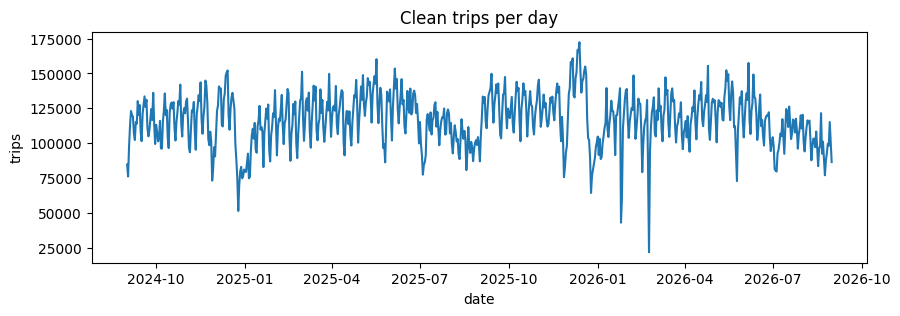

In [7]:
# 1.7 check and save
rows, pickups, n_zones = con.sql(f'SELECT COUNT(*), SUM(pickups)::BIGINT, COUNT(DISTINCT zone)'
                                 f"FROM '{AGG}/demand_zone_hour.parquet'").fetchone()
n_trips = con.sql('SELECT COUNT(*) FROM trips').fetchone()[0]
# sanity check
assert n_trips == quality.kept.sum(), "trips table doesn't match kept rows"
assert pickups == n_trips, "demand table doesn't add up to trips"
assert n_zones == 263, "demand grid missing zones"
assert (quality.kept_pct > 80).all(), f"a month lost >10% of rows:\n{quality[quality.kept_pct <= 85]}"
print(f"checked {n_trips:,} clean trips, {rows:,} zone-hours, all checks passed")
# visual check
ax = daily.plot(x="date", y="trips", figsize=(10, 3), legend=False, title="Clean trips per day")
ax.set_ylabel("trips")

db = duckdb.connect(str(BASE / "taxi.duckdb"))
db.execute(f"CREATE OR REPLACE VIEW trips AS SELECT * FROM read_parquet('{CLEAN}/*/*/*.parquet', hive_partitioning=false)")
db.execute(f"CREATE OR REPLACE VIEW demand_zone_hour AS SELECT * FROM '{AGG}/demand_zone_hour.parquet'")
db.execute(f"CREATE OR REPLACE VIEW daily_summary AS SELECT * FROM '{AGG}/daily_summary.parquet'")
db.execute(f"CREATE OR REPLACE TABLE zones AS SELECT * FROM read_csv_auto('{RAW}/taxi_zone_lookup.csv')")
db.close()
print("Saved", BASE / "taxi.duckdb")
